    Loan_ID Gender Married Dependents     Education Self_Employed  \
0  LP001002   Male      No          0      Graduate            No   
1  LP001003   Male     Yes          1      Graduate            No   
2  LP001005   Male     Yes          0      Graduate           Yes   
3  LP001006   Male     Yes          0  Not Graduate            No   
4  LP001008   Male      No          0      Graduate            No   

   ApplicantIncome  CoapplicantIncome  LoanAmount  Loan_Amount_Term  \
0             5849                0.0         NaN             360.0   
1             4583             1508.0       128.0             360.0   
2             3000                0.0        66.0             360.0   
3             2583             2358.0       120.0             360.0   
4             6000                0.0       141.0             360.0   

   Credit_History Property_Area Loan_Status  
0             1.0         Urban           Y  
1             1.0         Rural           N  
2             1.0   

C:\Users\kumkum rathor\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



========== FINSIGHT ==========
Dataset Size : 614
Training Data: 491
Testing Data : 123
Accuracy     : 85.37 %

Confusion Matrix:
[[21 17]
 [ 1 84]]


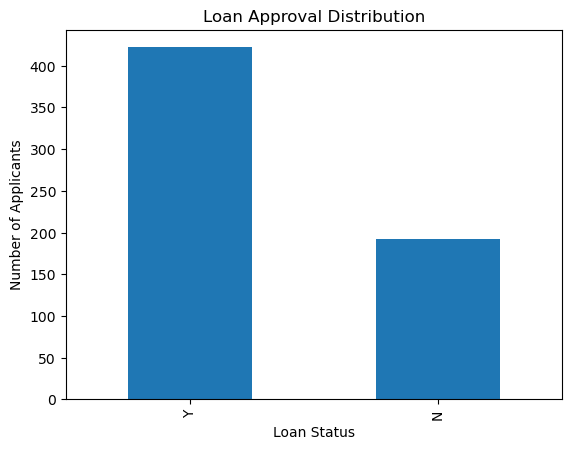

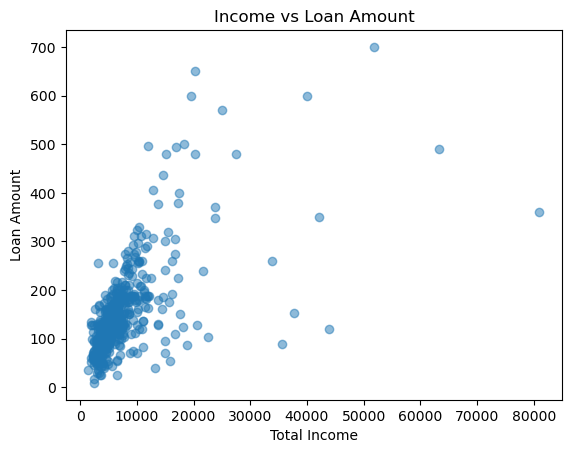


FinSight Completed Successfully!


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Load dataset
df = pd.read_csv(
    r"C:\Users\kumkum rathor\Deep learning project\train_u6lujuX_CVtuZ9i (1).csv"
)

# 2. Check data
print(df.head())
print(df.shape)
print(df.isnull().sum())

# 3. Fill missing values
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])
df["Married"] = df["Married"].fillna(df["Married"].mode()[0])
df["Dependents"] = df["Dependents"].fillna(df["Dependents"].mode()[0])
df["Self_Employed"] = df["Self_Employed"].fillna(df["Self_Employed"].mode()[0])
df["LoanAmount"] = df["LoanAmount"].fillna(df["LoanAmount"].median())
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].fillna(
    df["Loan_Amount_Term"].mode()[0]
)
df["Credit_History"] = df["Credit_History"].fillna(
    df["Credit_History"].mode()[0]
)

# 4. Create total income
df["TotalIncome"] = (
    df["ApplicantIncome"] + df["CoapplicantIncome"]
)

# 5. Select useful features
features = [
    "TotalIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History",
    "Education",
    "Self_Employed",
    "Property_Area"
]

X = df[features]
y = df["Loan_Status"].map({"Y": 1, "N": 0})

# 6. Convert categorical variables
X = pd.get_dummies(
    X,
    columns=["Education", "Self_Employed", "Property_Area"],
    drop_first=True
)

X = X.astype(float)

# 7. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 8. Train Logistic Regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# 9. Prediction
y_pred = model.predict(X_test)

# 10. Evaluation
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("\n========== FINSIGHT ==========")
print("Dataset Size :", len(df))
print("Training Data:", len(X_train))
print("Testing Data :", len(X_test))
print("Accuracy     :", round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(cm)

# 11. Loan status distribution
df["Loan_Status"].value_counts().plot(
    kind="bar",
    title="Loan Approval Distribution"
)
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.show()

# 12. Income vs Loan Amount
plt.scatter(df["TotalIncome"], df["LoanAmount"], alpha=0.5)
plt.xlabel("Total Income")
plt.ylabel("Loan Amount")
plt.title("Income vs Loan Amount")
plt.show()


print("\nFinSight Completed Successfully!")

========== FINSIGHT ==========
Dataset Size : 614
Training Data: 491
Testing Data : 123
Accuracy     : 85.37 %

Confusion Matrix:
[[21 17]
 [ 1 84]]


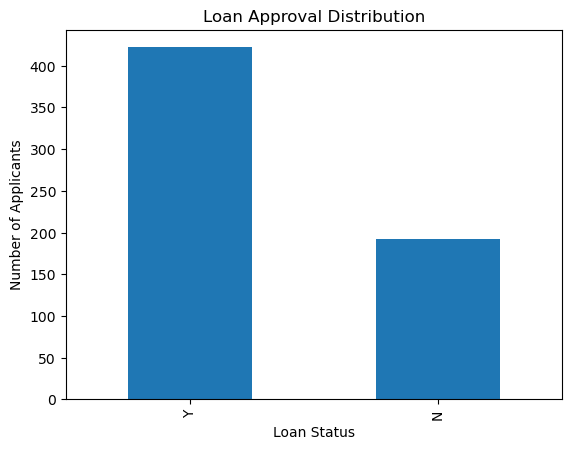

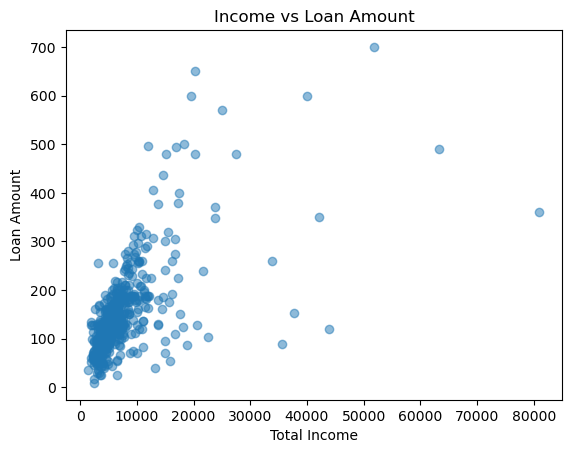


FinSight Completed Successfully!


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Load dataset
df = pd.read_csv("train_u6lujuX_CVtuZ9i (1).csv")

# 2. Fill missing values
df["Gender"] = df["Gender"].fillna(df["Gender"].mode()[0])
df["Married"] = df["Married"].fillna(df["Married"].mode()[0])
df["Dependents"] = df["Dependents"].fillna(df["Dependents"].mode()[0])
df["Self_Employed"] = df["Self_Employed"].fillna(
    df["Self_Employed"].mode()[0]
)
df["LoanAmount"] = df["LoanAmount"].fillna(
    df["LoanAmount"].median()
)
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].fillna(
    df["Loan_Amount_Term"].mode()[0]
)
df["Credit_History"] = df["Credit_History"].fillna(
    df["Credit_History"].mode()[0]
)

# 3. Feature engineering
df["TotalIncome"] = (
    df["ApplicantIncome"] + df["CoapplicantIncome"]
)

# 4. Select important features
features = [
    "TotalIncome",
    "LoanAmount",
    "Loan_Amount_Term",
    "Credit_History",
    "Education",
    "Self_Employed",
    "Property_Area"
]

X = df[features]
y = df["Loan_Status"].map({"Y": 1, "N": 0})

# 5. Convert categorical data
X = pd.get_dummies(
    X,
    columns=["Education", "Self_Employed", "Property_Area"],
    drop_first=True
)

# 6. Convert values to numbers
X = X.astype(float)

# 7. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 8. Scale numerical features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 9. Train Logistic Regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# 10. Prediction
y_pred = model.predict(X_test)

# 11. Evaluation
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("========== FINSIGHT ==========")
print("Dataset Size :", len(df))
print("Training Data:", len(X_train))
print("Testing Data :", len(X_test))
print("Accuracy     :", round(accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(cm)

# 12. Loan approval distribution
df["Loan_Status"].value_counts().plot(
    kind="bar",
    title="Loan Approval Distribution"
)
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.show()

# 13. Income vs Loan Amount
plt.scatter(
    df["TotalIncome"],
    df["LoanAmount"],
    alpha=0.5
)
plt.xlabel("Total Income")
plt.ylabel("Loan Amount")
plt.title("Income vs Loan Amount")
plt.show()

print("\nFinSight Completed Successfully!")